# Group theory 10: Error-correcting codes

*Learning path: group theory, part 10 of 10.* [Index](README.md) · Previous: [Ruler and compass](09-ruler-and-compass.ipynb)

**The question.** Scratch a CD, smudge a QR code, or send a photo from Saturn across 1.4 billion kilometres of radio
noise, and the data still comes through intact. Not because nothing went wrong, but because the sender added just
enough extra information for the receiver to find and repair the damage. How can a few extra symbols locate an error
you know nothing about? The answers are linear algebra over $\mathbb F_2$ and polynomials over finite fields, the
algebra of the last few lessons put to work.

**Who this is for:** anyone who has done lessons [5](05-rings-and-fields.ipynb) and
[8](08-polynomials-over-fields.ipynb). **You need:** arithmetic mod 2, matrices, finite fields `gf(q)`.

**You will learn**

* the **Hamming distance**, and why a code with minimum distance $d$ corrects $\lfloor(d-1)/2\rfloor$ errors,
* the **Hamming code**: 4 data bits, 3 check bits, and a **syndrome** that spells out the position of an error,
* why the Hamming code is **perfect**,
* **Reed–Solomon codes**: a message as a polynomial over a finite field, sent as its values,
* how two damaged symbols are found and repaired, and where these codes are used.

## 1. Distance

Send each bit three times: 0 becomes 000, 1 becomes 111. If one of the three flips, a majority vote repairs it. The
price is high: three bits sent for each bit of data. Can we do better?

Think of the codewords as points in the space of all bit strings. The **Hamming distance** between two strings is the
number of places where they differ. If any two codewords differ in at least $d$ places, then after up to $t$ errors
with $2t < d$, the received string is still closer to the codeword that was sent than to any other. So a code with
**minimum distance** $d$ corrects $\lfloor (d-1)/2 \rfloor$ errors. The repetition code has $d = 3$ and corrects 1.
The goal: distance 3 with far fewer extra bits.

## 2. The Hamming code

Richard Hamming, tired of a relay computer at Bell Labs that stopped at every error over the weekend, found the answer
in 1950. Number the 7 positions of a codeword 1 to 7 and write the numbers in binary as the columns of a matrix:

In [1]:
H = [1 0 1 0 1 0 1; 0 1 1 0 0 1 1; 0 0 0 1 1 1 1]

[1, 0, 1, 0, 1, 0, 1;
 0, 1, 1, 0, 0, 1, 1;
 0, 0, 0, 1, 1, 1, 1]

The codewords are the strings $c$ with $Hc = 0$ modulo 2. Put the 4 data bits in positions 3, 5, 6 and 7, and choose
the **check bits** in positions 1, 2 and 4 (the powers of 2) to make each row's sum even:

In [2]:
function hamming(d)
  c = [0, 0, d(1), 0, d(2), d(3), d(4)];
  c(1) = mod(c(3) + c(5) + c(7), 2);
  c(2) = mod(c(3) + c(6) + c(7), 2);
  c(4) = mod(c(5) + c(6) + c(7), 2);
  return c
end
c = hamming([1, 0, 1, 1])
mod(H*c', 2)'

[0, 1, 1, 0, 0, 1, 1]
[0, 0, 0]

Now flip bit 6 on the way. The receiver computes the **syndrome** $s = Hr$:

In [3]:
r = c;
r(6) = 1 - r(6);
s = mod(H*r', 2)'
simplify(s(1) + 2*s(2) + 4*s(3))

[0, 1, 1]
6

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

Since $Hc = 0$, the syndrome of $r = c + e$ is $He$: the column of $H$ at the error's position, which is that position
written in binary. Here $011$ read backwards is 6, so bit 6 is flipped back. One error, anywhere, located with no
search at all. The codewords form a subspace of $\mathbb F_2^7$ of dimension 4 (the null space of $H$), and any two
differ in at least 3 places, because no one or two columns of $H$ add up to zero.

**Perfect.** Each of the $2^4 = 16$ codewords has 7 neighbours at distance 1, so it claims $1 + 7 = 8$ strings, and
$16 \times 8 = 128 = 2^7$: the balls of radius 1 fill the whole space with no gaps and no overlap. Every possible
received string is within distance 1 of exactly one codeword. Such **perfect codes** are rare: besides repetition and
Hamming codes there is only the binary Golay code of length 23 and a ternary one of length 11.

**Is it worth it?** If each bit flips with probability $p$, 4 unprotected bits arrive intact with probability
$(1-p)^4$, while a Hamming codeword survives when at most one of its 7 bits flips:

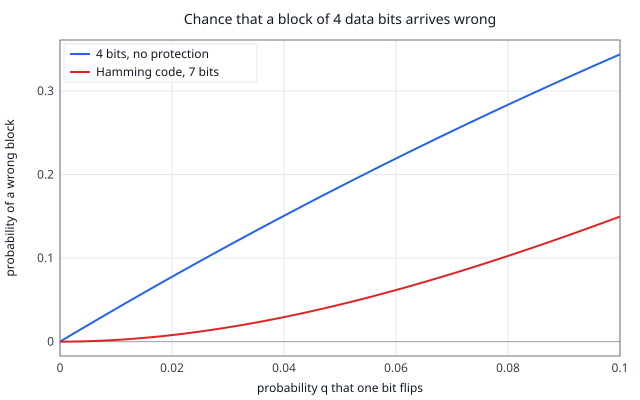

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
p = plot(1 - (1 - q)^4, q, 0, 0.1);
p = show(p, plot(1 - (1 - q)^7 - 7*q*(1 - q)^6, q, 0, 0.1));
p = legend(p, "4 bits, no protection", "Hamming code, 7 bits");
labels(title(p, "Chance that a block of 4 data bits arrives wrong"), "probability q that one bit flips", "probability of a wrong block")

At $q = 0.01$ the failure rate drops from 4% to 0.2%, for 75% more bits instead of the 200% of repetition.

**Try this.** Flip two bits of `c`, say 2 and 5. What does the syndrome say, and what goes wrong?

## 3. Reed–Solomon codes

Hamming codes fix one bit in seven. Scratches and smudges destroy whole bursts of bits. In 1960 Irving Reed and Gustave
Solomon proposed working with **symbols**, elements of a finite field, instead of bits, and using a simple fact about
polynomials: a polynomial of degree less than $k$ is determined by its values at any $k$ points.

Work in $\mathbb F_8$, whose 7 nonzero elements are the powers of a generator $a$ (lesson 5). The message is 3 symbols.
Make them the values at $1, a, a^2$ of the unique polynomial $f$ of degree at most 2, and send the values of $f$ at
all 7 points. Two codewords are different polynomials of degree at most 2, which agree in at most 2 places; so they
differ in at least 5, the distance is $d = 5$, and the code corrects $t = 2$ symbol errors.

In [5]:
F = gf(8);
a = F(a);
pts = {};
for k in 0:6
  pts = append(pts, a^k);
end
pts

{gf(8, 1), gf(8, a), gf(8, a^2), gf(8, a+1), gf(8, a^2+a), gf(8, a^2+a+1), gf(8, a^2+1)}

To find $f$ from three values, use **Lagrange interpolation**:
$f(x) = \sum_i y_i\prod_{j \ne i}\frac{x - x_j}{x_i - x_j}$. Every operation is field arithmetic in $\mathbb F_8$.

In [6]:
function lag(xs, ys, x)
  s = 0*x;
  for i in 1:length(xs)
    term = ys(i);
    for j in 1:length(xs)
      if j != i
        term = term*(x - xs(j))/(xs(i) - xs(j));
      end
    end
    s = s + term;
  end
  return s
end
function encode(msg, pts)
  xs = {pts(1), pts(2), pts(3)};
  c = {};
  for k in 1:7
    c = append(c, lag(xs, msg, pts(k)));
  end
  return c
end
msg = {a^2, F(1), a + 1};
c = encode(msg, pts)

{gf(8, a^2), gf(8, 1), gf(8, a+1), gf(8, 0), gf(8, a^2+a+1), gf(8, a^2+a), gf(8, a)}

> `encode`: encode turns a text into one whole number (its bytes in base 256); decode turns the number back into the text.

The first three symbols are the message itself; the last four are the check symbols. Now damage two symbols, the
second and the sixth:

In [7]:
r = c;
r(2) = r(2) + a;
r(6) = r(6) + F(1);
r

{gf(8, a^2), gf(8, a+1), gf(8, a+1), gf(8, 0), gf(8, a^2+a+1), gf(8, a^2+a+1), gf(8, a)}

**Decoding.** The receiver doesn't know which symbols are bad. But at least 5 of the 7 are good, and any 3 good ones
determine $f$. So try every choice of 3 positions, interpolate, and accept the polynomial that agrees with at least 5
received symbols. A wrong polynomial agrees with $f$ in at most 2 places, and so with at most $2 + 2 = 4$ received
symbols; only the true one reaches 5.

In [8]:
function decode(r, pts)
  for i in 1:5
    for j in i+1:6
      for k in j+1:7
        xs = {pts(i), pts(j), pts(k)};
        ys = {r(i), r(j), r(k)};
        agree = 0;
        for m in 1:7
          if lag(xs, ys, pts(m)) == r(m)
            agree = agree + 1;
          end
        end
        if agree >= 5
          return {lag(xs, ys, pts(1)), lag(xs, ys, pts(2)), lag(xs, ys, pts(3))}
        end
      end
    end
  end
  return "too many errors"
end
decode(r, pts)

{gf(8, a^2), gf(8, 1), gf(8, a+1)}

> `decode` (see `encode`): encode turns a text into one whole number (its bytes in base 256); decode turns the number back into the text.

The original message, recovered from a codeword with two of its seven symbols destroyed. Trying all $\binom73 = 35$
choices is fine here; real decoders (Berlekamp–Massey, 1968) find the error positions directly by solving for an
**error-locator polynomial**, fast enough for every frame of a video stream.

**Try this.** Damage three symbols. Does `decode` still recover the message? What does it return, and why can that
not be fixed?

## 4. Where these codes live

* **CDs and DVDs** use two Reed–Solomon codes over $\mathbb F_{256}$, interleaved so that a scratch spreads over
  many codewords: a CD player corrects bursts of about 4000 bits, 2.5 mm of track.
* **QR codes** use Reed–Solomon over $\mathbb F_{256}$, with four levels of protection; at the highest, 30% of the
  code can be covered by a logo and it still scans.
* **Voyager** sent its images of Uranus and Neptune with Reed–Solomon over $\mathbb F_{256}$ wrapped around a
  convolutional code, and still transmits from beyond the solar system with a 23-watt transmitter.
* **Memory chips** in servers use Hamming-style codes (with one extra parity bit to also detect double errors) to fix
  bit flips caused by cosmic rays.
* **RAID 6** disk arrays and cloud storage spread data with Reed–Solomon so that any two disks can fail.

## Exercises

1. **Repetition.** What is the minimum distance of the code that repeats each bit 5 times? How many errors does it
   correct?
2. **All codewords.** List all 16 Hamming codewords with `hamming` and check that the smallest distance between two
   of them is 3. (Because the code is linear, it is enough to find the smallest number of 1s in a nonzero codeword.)
3. **Extended Hamming.** Add an 8th bit, the parity of the other 7. Show that the new code has distance 4: it still
   corrects one error, and now detects two.
4. **Erasures.** If the receiver knows *which* symbols are lost (an erasure, like a missing packet), Reed–Solomon can
   repair $n - k$ of them. Recover the message of section 3 from symbols 4, 5 and 7 alone.
5. **Singleton bound.** Show that any code of length $n$ with $q^k$ codewords has distance at most $n - k + 1$.
   (Delete $d - 1$ positions.) Reed–Solomon codes meet this bound.
6. **Bigger field.** With $\mathbb F_{16}$ and messages of 11 symbols, a Reed–Solomon codeword has 15 symbols. How
   many symbol errors does it correct?

## Summary

* A code with minimum distance $d$ corrects $\lfloor (d-1)/2\rfloor$ errors.
* The Hamming code adds 3 check bits to 4 data bits; the syndrome $Hr$ is the error's position in binary; the code is
  perfect.
* Reed–Solomon codes send a polynomial of degree less than $k$ as its values at $n$ points of a finite field; distance
  $n - k + 1$, so they correct $(n-k)/2$ symbol errors.
* CDs, QR codes, deep-space probes, memory and disk arrays all rely on them.

## Hints and answers

* **Section 2, Try this.** The syndrome is $010 + 101 = 111$, position 7: the decoder flips a third bit and makes it
  worse. Distance 3 corrects one error, not two.
* **Section 3, Try this.** Usually it finds no polynomial with 5 agreements and returns "too many errors"; with three
  errors the received word can even be within distance 2 of another codeword, which no decoder can tell apart.
* **Exercise 1.** $d = 5$, corrects 2.
* **Exercise 2.** The codewords with fewest 1s, like `hamming([1, 0, 0, 0])` = 1110000, have three.
* **Exercise 3.** Codewords of weight 3 become weight 4; odd weights disappear, so the minimum is 4.
* **Exercise 4.** `lag({pts(4), pts(5), pts(7)}, {c(4), c(5), c(7)}, pts(k))` for $k = 1, 2, 3$.
* **Exercise 5.** Deleting $d - 1$ positions keeps codewords distinct, leaving $q^k$ distinct strings of length
  $n - d + 1$, so $q^k \le q^{n-d+1}$.
* **Exercise 6.** $d = 15 - 11 + 1 = 5$: two symbol errors.

## Sources

1. R. W. Hamming, "Error detecting and error correcting codes", *Bell System Technical Journal* 29, 147–160 (1950).
2. I. S. Reed and G. Solomon, "Polynomial codes over certain finite fields", *Journal of the Society for Industrial
   and Applied Mathematics* 8, 300–304 (1960).
3. E. R. Berlekamp, *Algebraic Coding Theory*, McGraw-Hill (1968).
4. K. A. S. Immink, "Reed–Solomon codes and the compact disc", in S. B. Wicker and V. K. Bhargava (eds.),
   *Reed–Solomon Codes and Their Applications*, IEEE Press (1994).
5. F. J. MacWilliams and N. J. A. Sloane, *The Theory of Error-Correcting Codes*, North-Holland (1977).